# 05 · RQ3 · Góc nhìn một ngân hàng

**Câu hỏi nghiên cứu.** Một ngân hàng chỉ thấy các giao dịch có khách hàng của mình ở một đầu. Với các vòng tiền mà RQ2 tìm được, một ngân hàng đơn lẻ thấy trọn được bao nhiêu vòng, và nếu không thấy trọn thì thấy được bao nhiêu phần?

Notebook đọc danh sách vòng của `04_rq2_loops.ipynb` (`reports/rq2/rq2_loops_<view>_<đoạn>.csv`) và đồ thị của `02_graph.ipynb`, ghi kết quả vào `reports/rq3/`. Không có tham số nào để chọn; nhãn chỉ dùng để tách vòng rửa tiền và vòng thường khi báo cáo.

**Định nghĩa.** Mỗi vòng được xét qua dãy giao dịch chứng minh của nó (`witness_ids`, một giao dịch cho mỗi chặng).
- Ngân hàng $b$ **thấy** một chặng nếu tài khoản gửi hoặc tài khoản nhận của chặng đó thuộc $b$.
- $b$ **thấy trọn** vòng nếu $b$ thấy mọi chặng.
- **Độ phủ tốt nhất** của vòng = tỷ lệ chặng mà ngân hàng thấy nhiều chặng nhất nhìn thấy.
- **Số ngân hàng tối thiểu** = số ngân hàng ít nhất cần ghép dữ liệu để thấy mọi chặng (bài toán phủ tập nhỏ, giải vét cạn vì mỗi vòng chỉ có 3–6 chặng).

| Mục | Nội dung | Đầu ra |
|---|---|---|
| 1–2 | Đầu vào; ghép ngân hàng và nhãn cho từng chặng | |
| 3 | Từng vòng: số ngân hàng, thấy trọn, độ phủ tốt nhất, số ngân hàng tối thiểu | `rq3_loops.csv` |
| 4 | Tổng hợp theo đoạn và nhóm (toàn rửa tiền / không rửa tiền), theo ring | `rq3_summary.csv`, `rq3_rings.csv` |
| 5 | Những vòng một ngân hàng thấy trọn | `rq3_single_bank_loops.csv` |
| 6 | Độ vững: đồ thị mọi định dạng | `rq3_summary_all_formats.csv` |
| 7 | Hình và kết luận | `rq3_bank_view.png`, `rq3_decision.json` |

Ngoài phạm vi: đường cong chia sẻ dữ liệu giữa nhiều ngân hàng (consortium) đầy đủ.

## 1. Đầu vào

In [1]:
import itertools
import json
import os
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

GRAPH_REL = Path("data") / "processed" / "graph" / "graph_edges.parquet"


def find_project_root():
    """HI_SMALL_ROOT nếu đã đặt; nếu không, tìm thư mục chứa đầu ra của notebook 01–04."""
    if os.environ.get("HI_SMALL_ROOT"):
        return Path(os.environ["HI_SMALL_ROOT"]).expanduser()
    here = Path.cwd()
    for folder in (Path("/kaggle/working"), here, here.parent,
                   here / "IBM_HI_Small_EDA", here.parent / "IBM_HI_Small_EDA"):
        if (folder / GRAPH_REL).is_file():
            return folder
    raise FileNotFoundError(f"Không tìm thấy {GRAPH_REL}. Chạy 01 → 04 trước, hoặc đặt biến môi trường HI_SMALL_ROOT.")


ROOT = find_project_root().resolve()
EDGES_FILE = ROOT / GRAPH_REL
TXN_FILE = ROOT / "data" / "processed" / "hi_small_graph_transactions.parquet"
RQ2 = ROOT / "reports" / "rq2"
OUT = ROOT / "reports" / "rq3"
OUT.mkdir(parents=True, exist_ok=True)
SEGMENTS = ["dev", "test"]
VIEWS = ["ACH", "ALL"]
LENGTHS = (3, 6)                      # như quy tắc chính của RQ2

need = [EDGES_FILE, TXN_FILE] + [RQ2 / f"rq2_loops_{v}_{s}.csv" for v in VIEWS for s in SEGMENTS]
missing = [str(f) for f in need if not f.is_file()]
if missing:
    raise FileNotFoundError("Thiếu đầu vào (chạy 04_rq2_loops.ipynb trước):\n  " + "\n  ".join(missing))
print(f"Thư mục dự án: {ROOT}")

db = duckdb.connect()
_ = db.execute("SET threads = 4")
DUCKDB_TMP = ROOT / "data" / "duckdb_tmp"
DUCKDB_TMP.mkdir(parents=True, exist_ok=True)
_ = db.execute(f"SET memory_limit = '{os.environ.get('HI_SMALL_DUCKDB_MEMORY', '2GB')}'")
_ = db.execute(f"SET temp_directory = '{DUCKDB_TMP.as_posix()}'")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

Thư mục dự án: D:\KLTN


## 2. Vòng của RQ2 và thông tin từng chặng

Chỉ lấy vòng dài 3–6, tăng nghiêm ngặt, ≤ δ (cột `strict_delta`), đúng như quy tắc chính của RQ2. Mỗi chặng được ghép với mã ngân hàng hai đầu (từ `graph_edges`) và nhãn (từ tập giao dịch của notebook 01).

In [2]:
loops = []
for view in VIEWS:
    for seg in SEGMENTS:
        c = pd.read_csv(RQ2 / f"rq2_loops_{view}_{seg}.csv")
        c = c[c.strict_delta.astype(bool) & c.length.between(*LENGTHS)].copy()
        c.insert(0, "segment", seg)
        c.insert(0, "view", view)
        loops.append(c)
loops = pd.concat(loops, ignore_index=True)
loops["ids"] = loops.witness_ids.str.split().apply(lambda x: [int(i) for i in x])

all_ids = sorted({i for x in loops.ids for i in x})
hop = db.execute("""
    SELECT e.transaction_id, e.from_bank_id, e.to_bank_id, e.src, e.dst, t.is_laundering
    FROM read_parquet(?) e JOIN read_parquet(?) t USING (transaction_id)
    WHERE list_contains(?::BIGINT[], e.transaction_id)
""", [str(EDGES_FILE), str(TXN_FILE), all_ids]).df().set_index("transaction_id")
assert set(hop.index) == set(all_ids), "Có giao dịch chứng minh không tìm thấy trong graph_edges."
display(loops.groupby(["view", "segment"]).size().rename("số vòng 3–6 đúng thứ tự, ≤ δ").to_frame())

số vòng 3–6 đúng thứ tự, ≤ δ
view segment                              
ACH  dev                                48
     test                               40
ALL  dev                                55
     test                               41

## 3. Từng vòng: ngân hàng thấy được gì

Với mỗi vòng: số ngân hàng chạm tới, có ngân hàng nào thấy trọn không, độ phủ tốt nhất của một ngân hàng, số ngân hàng tối thiểu cần ghép để thấy trọn, và ring của vòng (nhóm tài khoản nối với nhau qua các vòng, cùng cách tính với `04_rq2_loops.ipynb`).

In [3]:
def min_banks(hop_sets):
    """Số ngân hàng ít nhất sao cho mỗi chặng có ít nhất một đầu thuộc một trong các ngân hàng đó."""
    banks = sorted(set().union(*hop_sets))
    for k in range(1, len(banks) + 1):
        for combo in itertools.combinations(banks, k):
            chosen = set(combo)
            if all(h & chosen for h in hop_sets):
                return k
    return len(banks)


def ring_ids(accounts_col):
    parent = {}

    def find(x):
        parent.setdefault(x, x)
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    for acc in accounts_col:
        a = acc.split(" > ")
        for x in a[1:]:
            ra, rb = find(a[0]), find(x)
            if ra != rb:
                parent[rb] = ra
    return accounts_col.apply(lambda s: find(s.split(" > ")[0]))


rows = []
for r in loops.itertuples():
    h = hop.loc[r.ids]
    hop_sets = [{int(a), int(b)} for a, b in zip(h.from_bank_id, h.to_bank_id)]
    banks = set().union(*hop_sets)
    seen = {b: sum(b in s for s in hop_sets) for b in banks}
    best_bank = max(sorted(seen), key=lambda b: seen[b])
    full = sorted(b for b in banks if seen[b] == len(hop_sets))
    accounts_banks = {int(k.split("_")[0]) for k in list(h.src) + list(h.dst)}
    n_laund = int(h.is_laundering.sum())
    rows.append({
        "view": r.view, "segment": r.segment, "cycle_id": int(r.cycle_id), "length": int(r.length),
        "accounts": r.accounts, "witness_ids": r.witness_ids,
        "n_banks": len(banks), "one_bank_sees_all": bool(full), "banks_seeing_all": " ".join(map(str, full)),
        "best_bank": best_bank, "best_coverage": seen[best_bank] / len(hop_sets),
        "min_banks_needed": min_banks(hop_sets), "intra_bank": len(accounts_banks) == 1,
        "n_laundering": n_laund, "fully_laundering": n_laund == len(hop_sets), "no_laundering": n_laund == 0,
    })
per_loop = pd.DataFrame(rows)
per_loop["ring"] = per_loop.groupby(["view", "segment"], group_keys=False).accounts.apply(ring_ids)
per_loop["group"] = np.select([per_loop.fully_laundering, per_loop.no_laundering],
                              ["toàn rửa tiền", "không rửa tiền"], "lẫn")
per_loop.to_csv(OUT / "rq3_loops.csv", index=False)
display(per_loop[(per_loop.view == "ACH") & (per_loop.segment == "test")]
        [["cycle_id", "length", "group", "n_banks", "one_bank_sees_all", "best_coverage", "min_banks_needed", "ring"]]
        .sort_values(["group", "cycle_id"]).round(2))

,cycle_id,length,group,n_banks,one_bank_sees_all,best_coverage,min_banks_needed,ring
55,747,3,không rửa tiền,3,False,0.67,2,77170
57,758,3,không rửa tiền,3,False,0.67,2,181002
63,774,3,không rửa tiền,3,False,0.67,2,2503
64,776,3,không rửa tiền,3,False,0.67,2,14758
65,780,3,không rửa tiền,3,False,0.67,2,15481
66,786,3,không rửa tiền,3,False,0.67,2,55764
67,790,3,không rửa tiền,3,False,0.67,2,56390
68,793,3,không rửa tiền,2,True,1.00,1,72234
69,797,3,không rửa tiền,3,False,0.67,2,88379
72,806,3,không rửa tiền,3,False,0.67,2,132001


## 4. Tổng hợp theo đoạn, nhóm và ring

Báo cáo cho mọi vòng, vòng toàn rửa tiền và vòng không rửa tiền. Vì các vòng trong cùng một ring không độc lập, bảng thứ hai tính theo **ring**: một ring được coi là một ngân hàng thấy trọn nếu ít nhất một vòng của ring được một ngân hàng thấy trọn.

In [4]:
def frac(x):
    return f"{int(x.sum())}/{len(x)} ({x.mean():.0%})" if len(x) else "0/0"


def summarize(df):
    out = []
    for (view, seg), g in df.groupby(["view", "segment"], sort=False):
        for name, part in (("mọi vòng", g), ("toàn rửa tiền", g[g.fully_laundering]), ("không rửa tiền", g[g.no_laundering])):
            if not len(part):
                continue
            out.append({"view": view, "segment": seg, "group": name, "loops": len(part),
                        "one_bank_sees_all": frac(part.one_bank_sees_all),
                        "best_coverage_median": part.best_coverage.median(),
                        "min_banks_1": int((part.min_banks_needed == 1).sum()),
                        "min_banks_2": int((part.min_banks_needed == 2).sum()),
                        "min_banks_3plus": int((part.min_banks_needed >= 3).sum()),
                        "banks_per_loop": f"{part.n_banks.min()}–{part.n_banks.median():.0f}–{part.n_banks.max()}"})
    return pd.DataFrame(out)


ach = per_loop[per_loop.view == "ACH"]
summary = summarize(ach)
summary.to_csv(OUT / "rq3_summary.csv", index=False)
print("ACH · theo vòng (banks_per_loop = nhỏ nhất–trung vị–lớn nhất):")
display(summary.round(2))

rings = (ach.groupby(["segment", "ring"], sort=False)
         .agg(loops=("cycle_id", "size"), fully_laundering_loops=("fully_laundering", "sum"),
              any_loop_seen_by_one_bank=("one_bank_sees_all", "any"), min_banks_needed=("min_banks_needed", "min"),
              banks=("n_banks", "max")).reset_index())
rings["laundering_ring"] = rings.fully_laundering_loops > 0
rings.to_csv(OUT / "rq3_rings.csv", index=False)
ring_summary = (rings.groupby(["segment", "laundering_ring"], sort=False)
                .agg(rings=("ring", "size"), seen_by_one_bank=("any_loop_seen_by_one_bank", "sum"))
                .reset_index())
print("ACH · theo ring:")
display(ring_summary)

banks_dist = ach.pivot_table(index="n_banks", columns="segment", values="cycle_id", aggfunc="size", fill_value=0)
banks_dist.to_csv(OUT / "rq3_banks_per_loop.csv")
display(banks_dist.rename_axis("số ngân hàng trên vòng"))

t = ach[ach.segment == "test"]
tf = t[t.fully_laundering]
print(f"Ý nghĩa: trên test, một ngân hàng đơn lẻ thấy trọn {frac(t.one_bank_sees_all)} vòng và {frac(tf.one_bank_sees_all)} "
      f"vòng toàn rửa tiền. Ngân hàng nhìn rõ nhất thường chỉ thấy {t.best_coverage.median():.0%} số chặng (trung vị); "
      f"{int((t.min_banks_needed >= 2).sum())}/{len(t)} vòng cần ít nhất hai ngân hàng ghép dữ liệu mới thấy trọn.")

ACH · theo vòng (banks_per_loop = nhỏ nhất–trung vị–lớn nhất):


,view,segment,group,loops,one_bank_sees_all,best_coverage_median,min_banks_1,min_banks_2,min_banks_3plus,banks_per_loop
0,ACH,dev,mọi vòng,48,4/48 (8%),0.67,4,42,2,2–3–6
1,ACH,dev,toàn rửa tiền,18,1/18 (6%),0.67,1,16,1,2–3–5
2,ACH,dev,không rửa tiền,28,2/28 (7%),0.67,2,26,0,2–3–3
3,ACH,test,mọi vòng,40,5/40 (12%),0.67,5,33,2,2–3–5
4,ACH,test,toàn rửa tiền,19,3/19 (16%),0.67,3,16,0,2–3–5
5,ACH,test,không rửa tiền,17,1/17 (6%),0.67,1,16,0,2–3–4


ACH · theo ring:


,segment,laundering_ring,rings,seen_by_one_bank
0,dev,True,5,1
1,dev,False,28,2
2,test,False,16,1
3,test,True,4,2


segment,dev,test
số ngân hàng trên vòng,,
2,4,4
3,36,26
4,6,7
5,1,3
6,1,0


Ý nghĩa: trên test, một ngân hàng đơn lẻ thấy trọn 5/40 (12%) vòng và 3/19 (16%) vòng toàn rửa tiền. Ngân hàng nhìn rõ nhất thường chỉ thấy 67% số chặng (trung vị); 35/40 vòng cần ít nhất hai ngân hàng ghép dữ liệu mới thấy trọn.


## 5. Những vòng một ngân hàng thấy trọn

Một ngân hàng thấy trọn vòng khi mọi chặng đều chạm tới nó. Trường hợp dễ nhất là **vòng nội bộ** (mọi tài khoản cùng một ngân hàng). Bảng cho biết các vòng đó thuộc ngân hàng nào và có phải vòng nội bộ không.

In [5]:
single = per_loop[per_loop.one_bank_sees_all][["view", "segment", "cycle_id", "length", "group", "banks_seeing_all",
                                               "n_banks", "intra_bank", "ring"]]
single.to_csv(OUT / "rq3_single_bank_loops.csv", index=False)
display(single[single.view == "ACH"])
s_test = single[(single.view == "ACH") & (single.segment == "test")]
n_intra = int(s_test.intra_bank.sum())
top_bank = single[single.view == "ACH"].banks_seeing_all.str.split().explode().value_counts()
print(f"Ý nghĩa: trên test có {len(s_test)} vòng một ngân hàng thấy trọn; "
      + (f"{n_intra} trong số đó là vòng nội bộ một ngân hàng. " if n_intra else "không vòng nào là vòng nội bộ một ngân hàng: ")
      + "ngân hàng đó giữ ít nhất một đầu của mọi chặng."
      + (f" Ngân hàng {top_bank.index[0]} xuất hiện ở {top_bank.iloc[0]} vòng như vậy (dev và test)." if len(top_bank) and top_bank.iloc[0] > 1 else ""))

,view,segment,cycle_id,length,group,banks_seeing_all,n_banks,intra_bank,ring
19,ACH,dev,1086,3,lẫn,148350,2,False,105153
20,ACH,dev,1088,3,toàn rửa tiền,148350,2,False,105153
21,ACH,dev,1092,3,không rửa tiền,3514,2,False,108435
26,ACH,dev,1128,3,không rửa tiền,211,2,False,166725
53,ACH,test,744,3,toàn rửa tiền,118,2,False,211692
60,ACH,test,763,4,toàn rửa tiền,222,3,False,211692
68,ACH,test,793,3,không rửa tiền,27,2,False,72234
70,ACH,test,800,3,toàn rửa tiền,148350,2,False,105153
71,ACH,test,802,3,lẫn,148350,2,False,105153


Ý nghĩa: trên test có 5 vòng một ngân hàng thấy trọn; không vòng nào là vòng nội bộ một ngân hàng: ngân hàng đó giữ ít nhất một đầu của mọi chặng. Ngân hàng 148350 xuất hiện ở 4 vòng như vậy (dev và test).


## 6. Độ vững: đồ thị mọi định dạng

Lặp lại bảng tổng hợp cho các vòng tìm được trên đồ thị mọi định dạng (view `ALL` của RQ2). Kết luận của RQ3 không nên phụ thuộc vào việc chỉ xét ACH.

In [6]:
summary_all = summarize(per_loop[per_loop.view == "ALL"])
summary_all.to_csv(OUT / "rq3_summary_all_formats.csv", index=False)
display(summary_all.round(2))

,view,segment,group,loops,one_bank_sees_all,best_coverage_median,min_banks_1,min_banks_2,min_banks_3plus,banks_per_loop
0,ALL,dev,mọi vòng,55,4/55 (7%),0.67,4,47,4,2–3–6
1,ALL,dev,toàn rửa tiền,18,1/18 (6%),0.67,1,16,1,2–3–5
2,ALL,dev,không rửa tiền,35,2/35 (6%),0.67,2,31,2,2–3–5
3,ALL,test,mọi vòng,41,5/41 (12%),0.67,5,34,2,2–3–5
4,ALL,test,toàn rửa tiền,19,3/19 (16%),0.67,3,16,0,2–3–5
5,ALL,test,không rửa tiền,17,1/17 (6%),0.67,1,16,0,2–3–4


## 7. Hình và kết luận

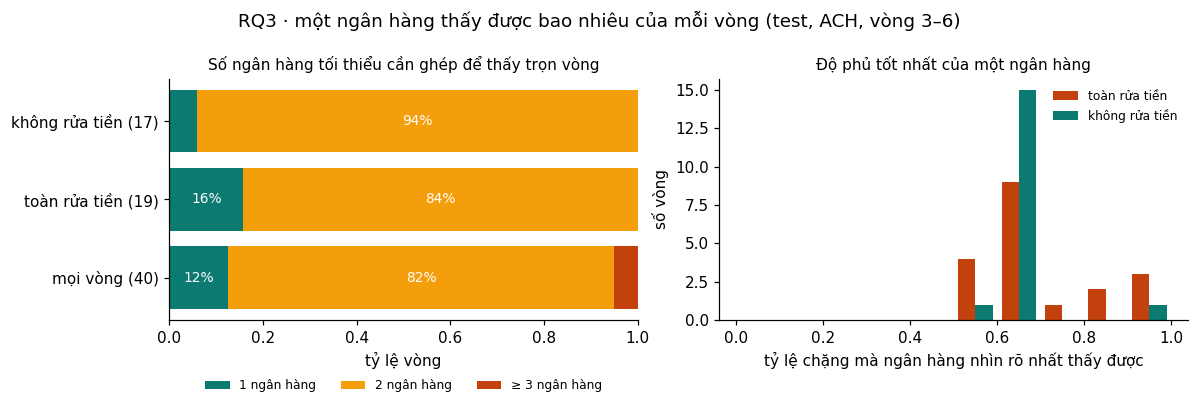

KẾT LUẬN RQ3: một ngân hàng đơn lẻ thấy trọn 3/19 (16%) vòng toàn rửa tiền trên test; tính theo ring, 2/4 ring rửa tiền có ít nhất một vòng mà một ngân hàng thấy trọn. Phần lớn vòng chỉ lộ ra khi ghép dữ liệu của hai ngân hàng trở lên.

Các file trong D:\KLTN\reports\rq3
   rq3_bank_view.png
   rq3_banks_per_loop.csv
   rq3_decision.json
   rq3_loops.csv
   rq3_loops_bank_view.csv
   rq3_rings.csv
   rq3_single_bank_loops.csv
   rq3_summary.csv
   rq3_summary_all_formats.csv


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
groups = [("mọi vòng", t), ("toàn rửa tiền", t[t.fully_laundering]), ("không rửa tiền", t[t.no_laundering])]
colors = {1: "#0B7A70", 2: "#F59E0B", 3: "#C2410C"}
ax = axes[0]
for i, (name, part) in enumerate(groups):
    left = 0.0
    for k, label in ((1, "1 ngân hàng"), (2, "2 ngân hàng"), (3, "≥ 3 ngân hàng")):
        share = ((part.min_banks_needed >= 3) if k == 3 else (part.min_banks_needed == k)).mean() if len(part) else 0
        ax.barh(i, share, left=left, color=colors[k], label=label if i == 0 else None)
        if share >= 0.08:
            ax.text(left + share / 2, i, f"{share:.0%}", ha="center", va="center", color="white", fontsize=9)
        left += share
ax.set_yticks(range(len(groups)), [f"{n} ({len(p)})" for n, p in groups])
ax.set_xlim(0, 1)
ax.set_xlabel("tỷ lệ vòng")
ax.set_title("Số ngân hàng tối thiểu cần ghép để thấy trọn vòng", fontsize=10)
ax.legend(fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)
ax = axes[1]
bins = np.linspace(0, 1, 11)
ax.hist([t[t.fully_laundering].best_coverage, t[t.no_laundering].best_coverage], bins=bins,
        color=["#C2410C", "#0B7A70"], label=["toàn rửa tiền", "không rửa tiền"])
ax.set_xlabel("tỷ lệ chặng mà ngân hàng nhìn rõ nhất thấy được")
ax.set_ylabel("số vòng")
ax.set_title("Độ phủ tốt nhất của một ngân hàng", fontsize=10)
ax.legend(fontsize=8, frameon=False)
fig.suptitle("RQ3 · một ngân hàng thấy được bao nhiêu của mỗi vòng (test, ACH, vòng 3–6)")
fig.tight_layout()
fig.savefig(OUT / "rq3_bank_view.png", bbox_inches="tight")
plt.show()

def pick(view, seg, group):
    row = summary_all if view == "ALL" else summary
    r = row[(row.segment == seg) & (row.group == group)]
    return r.iloc[0].to_dict() if len(r) else {}

decision = {
    "question": "Một ngân hàng đơn lẻ thấy trọn được bao nhiêu vòng rửa tiền mà RQ2 tìm thấy?",
    "test_ach_all_loops": pick("ACH", "test", "mọi vòng"),
    "test_ach_fully_laundering": pick("ACH", "test", "toàn rửa tiền"),
    "test_ach_no_laundering": pick("ACH", "test", "không rửa tiền"),
    "dev_ach_fully_laundering": pick("ACH", "dev", "toàn rửa tiền"),
    "test_all_formats_fully_laundering": pick("ALL", "test", "toàn rửa tiền"),
    "test_rings": ring_summary[ring_summary.segment == "test"].to_dict("records"),
    "note": "Kết quả sơ bộ trên số ít vòng (vài chục vòng, vài ring); không có tham số nào được chọn.",
}
(OUT / "rq3_decision.json").write_text(json.dumps(decision, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
lr = rings[(rings.segment == "test") & rings.laundering_ring]
print(f"KẾT LUẬN RQ3: một ngân hàng đơn lẻ thấy trọn {decision['test_ach_fully_laundering'].get('one_bank_sees_all')} vòng "
      f"toàn rửa tiền trên test; tính theo ring, {int(lr.any_loop_seen_by_one_bank.sum())}/{len(lr)} ring rửa tiền có ít nhất "
      "một vòng mà một ngân hàng thấy trọn. Phần lớn vòng chỉ lộ ra khi ghép dữ liệu của hai ngân hàng trở lên.")
print("\nCác file trong", OUT)
for f in sorted(OUT.iterdir()):
    print("  ", f.name)